# 05 · Outlier Detection
Module 4 (Outlier / Anomaly Detection)

An **outlier** is an observation that is very different from the rest of the data. It can be a measurement error,
a data-entry mistake, or a genuine but rare patient. We compare four detection methods:

| Family | Method | Idea |
|---|---|---|
| Statistical (univariate) | **IQR rule** | values beyond Q1 − 1.5·IQR or Q3 + 1.5·IQR |
| Statistical (univariate) | **Z-score** | values more than 3 standard deviations from the mean |
| Machine learning (multivariate) | **Isolation Forest** | outliers are easy to isolate with random splits |
| Machine learning (multivariate) | **Local Outlier Factor (LOF)** | outliers sit in regions much less dense than their neighbours |

### Setup
We import the usual libraries plus our own `src/` package. `src` holds all reusable code (statistics formulas, outlier detectors, model pipelines, plot styles) so the notebooks and the Streamlit app use exactly the same logic. The random seed is fixed to **42** so every run gives the same numbers.

In [1]:
import sys
from pathlib import Path

# Make the project root importable so we can use our own src/ package
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

from src import config as C
from src import data, plots
plots.set_style()
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
np.random.seed(C.RANDOM_STATE)
from src import outliers as O

## 1. Prepare the data - zeros are missing values, not outliers
Cholesterol = 0 and RestingBP = 0 are **impossible** values that mean "not recorded". If we left them in, every method would
flag them as extreme outliers - but they are a *missing data* problem (handled in notebook 06), not unusual patients.
So we drop those rows **for this analysis only**.

In [2]:
df = data.load_clean()
work = df.dropna(subset=C.ZERO_AS_MISSING).copy()
print(f"All patients: {len(df)}  ->  rows used for outlier analysis: {len(work)}  "
      f"(removed {len(df) - len(work)} rows with missing Cholesterol/RestingBP)")

All patients: 918  ->  rows used for outlier analysis: 746  (removed 172 rows with missing Cholesterol/RestingBP)


## 2. IQR method (Tukey fences)
$$ \text{lower fence} = Q_1 - 1.5 \times IQR, \qquad \text{upper fence} = Q_3 + 1.5 \times IQR $$
Anything outside the fences is an outlier. Because it uses quartiles, the rule is **robust**: the outliers themselves
barely move the fences. These are the same fences used for the whiskers of a box plot.

In [3]:
uni_cols = C.ZERO_AS_MISSING            # Cholesterol and RestingBP
rows = []
for col in uni_cols:
    lo, hi = O.iqr_bounds(work[col])
    flags = O.iqr_outliers(work[col])
    rows.append({"Feature": col, "Q1": work[col].quantile(.25), "Q3": work[col].quantile(.75),
                 "Lower fence": lo, "Upper fence": hi,
                 "Below": int((work[col] < lo).sum()), "Above": int((work[col] > hi).sum()), "Total flagged": int(flags.sum())})
pd.DataFrame(rows).set_index("Feature").round(2)

,Q1,Q3,Lower fence,Upper fence,Below,Above,Total flagged
Feature,,,,,,,
Cholesterol,207.250,275.000,105.620,376.620,3,20,23
RestingBP,120.000,140.000,90.000,170.000,0,20,20


## 3. Z-score method
$$ z = \frac{x - \bar x}{s} $$
The z-score says how many standard deviations a value is from the mean. For a normal distribution 99.7% of values
lie within ±3, so |z| > 3 is unusual. **Weakness:** the mean and standard deviation are themselves pulled by outliers,
and the rule assumes roughly normal data.

In [4]:
rows = []
for col in uni_cols:
    x = work[col]
    z = (x - x.mean()) / x.std()
    rows.append({"Feature": col, "Mean": x.mean(), "Std": x.std(),
                 "Value at z = −3": x.mean() - 3 * x.std(), "Value at z = +3": x.mean() + 3 * x.std(),
                 "Total flagged": int((z.abs() > 3).sum())})
pd.DataFrame(rows).set_index("Feature").round(2)

,Mean,Std,Value at z = −3,Value at z = +3,Total flagged
Feature,,,,,
Cholesterol,244.640,59.150,67.170,422.100,8
RestingBP,133.020,17.280,81.170,184.870,5


## 4. Isolation Forest and Local Outlier Factor
These two methods look at **all five continuous features together** (Age, RestingBP, Cholesterol, MaxHR, Oldpeak), so they can
find patients who are unusual in their *combination* of values even if no single value is extreme.

* Features are **standardised** first (mean 0, std 1) so that Cholesterol (hundreds) does not dominate Oldpeak (single digits).
* **Isolation Forest** builds 300 random trees that split the data at random points. Outliers end up alone after only a few splits.
* **LOF** compares the density around each point with the density around its 20 nearest neighbours; a much lower density = outlier.
* Both need a **contamination** setting (the expected share of outliers). We use **5%**, close to what the IQR rule finds,
  so the methods are compared on a similar scale.

In [5]:
flags = O.detect_all(work, uni_cols, C.CONTINUOUS, contamination=0.05)
flags.head()

,IQR,Z-score,Isolation Forest,LOF
0,False,False,False,False
1,False,False,False,False
2,False,False,False,True
3,False,False,False,False
4,False,False,False,False


## 5. Comparison table
How many rows each method flags (for IQR and z-score, a row is flagged if *either* Cholesterol or RestingBP is an outlier):

In [6]:
comp = O.comparison_table(flags)
comp

,Outliers flagged,% of rows
IQR,42,5.630
Z-score,13,1.740
Isolation Forest,38,5.090
LOF,38,5.090


### Overlap between methods
Cell (A, B) = number of rows flagged by **both** A and B (the diagonal is each method's own total).

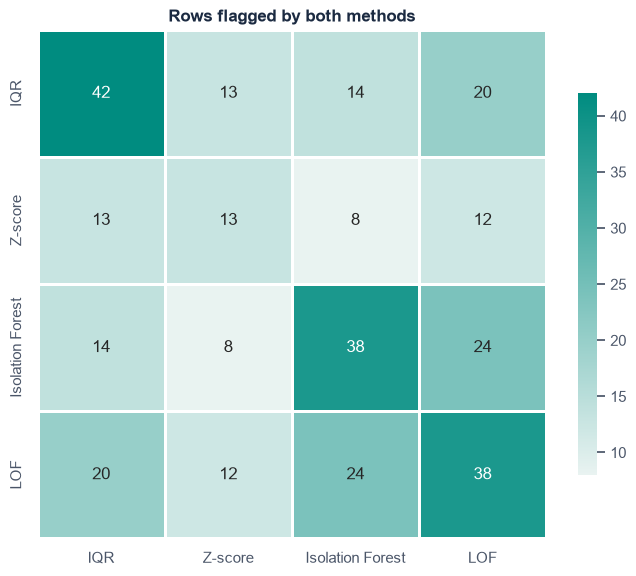

In [7]:
overlap = O.overlap_matrix(flags)
fig = plots.corr_heatmap(overlap, "Rows flagged by both methods", fmt="d", center=None,
                         cmap=sns.light_palette(C.TEAL, as_cmap=True))
plots.save_fig(fig, "05_outlier_overlap")
plt.show()

### How many methods agree on each row?

In [8]:
agree = O.agreement_summary(flags)
display(agree.T)
consensus = work[flags.all(axis=1)]
print(f"{len(consensus)} patients are flagged by ALL four methods:")
consensus[C.CONTINUOUS + [C.TARGET]]

Methods agreeing,0,1,2,3,4
Rows,676,31,25,6,8


8 patients are flagged by ALL four methods:


,Age,RestingBP,Cholesterol,MaxHR,Oldpeak,HeartDisease
76,32,118.000,529.000,130,0.000,1
109,39,190.000,241.000,106,0.000,0
149,54,130.000,603.000,125,1.000,1
241,54,200.000,198.000,142,2.000,1
496,58,132.000,458.000,69,1.000,0
616,67,115.000,564.000,160,1.600,0
732,56,200.000,288.000,133,4.000,1
759,54,192.000,283.000,195,0.000,1


## 6. Visualising the flagged points
Each panel shows Cholesterol vs RestingBP. Flagged points are coral; normal points are teal.
Notice that the multivariate methods sometimes flag points in the middle of this 2-D view - those patients are unusual
in Age, MaxHR or Oldpeak, which we cannot see in this projection.

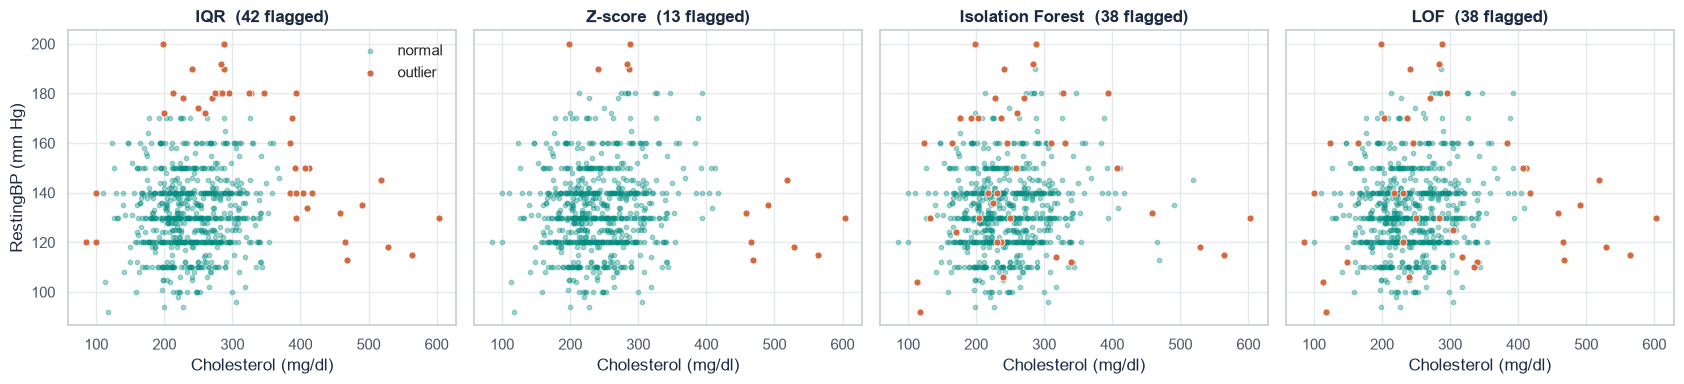

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4), sharex=True, sharey=True)
for ax, method in zip(axes, O.METHODS):
    f = flags[method]
    ax.scatter(work.loc[~f, "Cholesterol"], work.loc[~f, "RestingBP"], s=10, color=C.TEAL, alpha=0.35, label="normal")
    ax.scatter(work.loc[f, "Cholesterol"], work.loc[f, "RestingBP"], s=26, color=C.CLASS_COLORS[1],
               edgecolor="white", linewidth=0.6, label="outlier")
    ax.set_title(f"{method}  ({int(f.sum())} flagged)")
    ax.set_xlabel("Cholesterol (mg/dl)")
axes[0].set_ylabel("RestingBP (mm Hg)")
axes[0].legend(loc="upper right", frameon=False)
fig.tight_layout()
plots.save_fig(fig, "05_outlier_scatter")
plt.show()

Another view for the multivariate methods: Age vs MaxHR, where the ML methods find some patients the univariate rules miss.

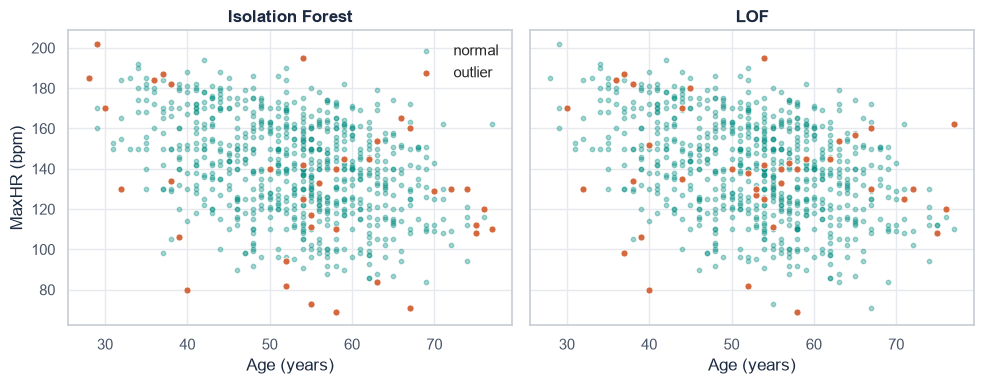

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, method in zip(axes, ["Isolation Forest", "LOF"]):
    f = flags[method]
    ax.scatter(work.loc[~f, "Age"], work.loc[~f, "MaxHR"], s=10, color=C.TEAL, alpha=0.35, label="normal")
    ax.scatter(work.loc[f, "Age"], work.loc[f, "MaxHR"], s=26, color=C.CLASS_COLORS[1],
               edgecolor="white", linewidth=0.6, label="outlier")
    ax.set_title(method)
    ax.set_xlabel("Age (years)")
axes[0].set_ylabel("MaxHR (bpm)")
axes[0].legend(frameon=False)
fig.tight_layout()
plots.save_fig(fig, "05_outlier_scatter_age_maxhr")
plt.show()

Save the flags so the app and later analysis can reuse them.

In [11]:
out = work[C.CONTINUOUS + [C.TARGET]].join(flags)
out.to_csv(C.PROCESSED_DIR / "outlier_flags.csv")
print("Saved:", (C.PROCESSED_DIR / "outlier_flags.csv").relative_to(C.ROOT))
print("Heart-disease rate among consensus outliers vs everyone:",
      f"{consensus[C.TARGET].mean():.1%} vs {work[C.TARGET].mean():.1%}")

Saved: data\processed\outlier_flags.csv
Heart-disease rate among consensus outliers vs everyone: 62.5% vs 47.7%


## 7. Discussion
**Statistical methods (IQR, z-score)**
* Simple, fast and easy to explain; work on **one feature at a time**.
* IQR is robust and does not assume normality; the z-score assumes a roughly normal shape and is itself influenced by the outliers
  (a very large cholesterol value inflates the standard deviation, which hides other outliers - the "masking" effect).
  That is why the z-score flags fewer points than IQR here.

**Distance / density-based methods (Isolation Forest, LOF)**
* Look at **several features together** and can find unusual *combinations* (e.g. a young patient with a very low MaxHR).
* Need scaling and a contamination parameter, and are harder to explain to a doctor.
* Isolation Forest finds *global* outliers (far from everything); LOF finds *local* outliers (in a sparse spot compared with neighbours).

**Why removing outliers in medical data needs care**
* An extreme value can be a **real, very sick patient** - e.g. cholesterol of 500+ mg/dl happens with familial hypercholesterolaemia.
  Deleting such patients removes exactly the high-risk cases a screening model must recognise.
* Only clear **errors** (impossible values such as 0 mm Hg) should be removed or treated as missing.
* For modelling we therefore **keep** the outliers and rely on robust choices instead: median imputation, standard scaling, and
  tree-based models that are not sensitive to extreme values.

## Key Findings
* After setting aside the 172 rows with missing Cholesterol/RestingBP, **746 patients** were analysed.
* The **IQR rule flags the most rows (42, 5.6%)**, the **z-score rule the fewest (13, 1.7%)** - the z-score is less sensitive because outliers inflate the standard deviation (masking).
* **Isolation Forest and LOF** each flag 38 rows (5% by design) but often **different** rows, because they use all five features and different ideas (global isolation vs local density).
* Only **8 patients are flagged by all four methods** - mostly patients with very high cholesterol and/or blood pressure; 676 rows are flagged by none.
* Outliers are **kept** for modelling: in medical data they are often genuine high-risk patients, not errors.